In [4]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# setting up basic display options.
sns.set(style="whitegrid")
plt.rcParams['figure.figsize'] = (10, 6)

# let's load our dataset.
df = pd.read_csv('indian_retail_customer_data.csv')

print("shape of the dataset:", df.shape)
print("\nfirst 5 rows:")
display(df.head())

print("\nbasic info about columns:")
df.info()

shape of the dataset: (541909, 8)

first 5 rows:


,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,States
0,536365,85123A,BRASS DIYA WITH OIL WICK HOLDER,6,01-12-2010 08:26,2.55,17850.0,Odisha
1,536365,71053,WHITE METAL LANTERN,6,01-12-2010 08:26,3.39,17850.0,Odisha
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,01-12-2010 08:26,2.75,17850.0,Odisha
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,01-12-2010 08:26,3.39,17850.0,Odisha
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,01-12-2010 08:26,3.39,17850.0,Odisha



basic info about columns:
<class 'pandas.DataFrame'>
RangeIndex: 541909 entries, 0 to 541908
Data columns (total 8 columns):
 #   Column       Non-Null Count   Dtype  
---  ------       --------------   -----  
 0   InvoiceNo    541909 non-null  str    
 1   StockCode    541909 non-null  str    
 2   Description  540455 non-null  str    
 3   Quantity     541909 non-null  int64  
 4   InvoiceDate  541909 non-null  str    
 5   UnitPrice    541909 non-null  float64
 6   CustomerID   406829 non-null  float64
 7   States       541909 non-null  str    
dtypes: float64(2), int64(1), str(5)
memory usage: 64.4 MB


In [5]:
## Data Cleaning.
# checking for null values in description or customer id
print("null counts:\n", df.isnull().sum())

# drop rows where customer id is missing because we need them for customer analysis
df = df.dropna(subset=['CustomerID', 'Description'])

# Some invoice numbers start with 'C' which may be cancellation/return. let's tag them.
df['is_return'] = df['InvoiceNo'].astype(str).str.startswith('C')

# removing negative quantities or zero unit prices just to be safe
df_clean = df[(df['Quantity'] > 0) & (df['UnitPrice'] > 0)].copy()

print("new shape after cleaning:", df_clean.shape)

null counts:
 InvoiceNo           0
StockCode           0
Description      1454
Quantity            0
InvoiceDate         0
UnitPrice           0
CustomerID     135080
States              0
dtype: int64
new shape after cleaning: (397884, 9)


In [6]:
# converting date column to actual datetime format using format='mixed' to prevent ValueError.
df_clean['InvoiceDate'] = pd.to_datetime(df_clean['InvoiceDate'], format='mixed')

# creating total revenue column (qty * price).
df_clean['Revenue'] = df_clean['Quantity'] * df_clean['UnitPrice']

# extracting month, day of week, and hour for time analysis.
df_clean['YearMonth'] = df_clean['InvoiceDate'].dt.to_period('M')
df_clean['Month'] = df_clean['InvoiceDate'].dt.month_name()
df_clean['DayOfWeek'] = df_clean['InvoiceDate'].dt.day_name()
df_clean['Hour'] = df_clean['InvoiceDate'].dt.hour

print("feature engineering done successfully!")
df_clean[['InvoiceNo', 'InvoiceDate', 'Quantity', 'UnitPrice', 'Revenue', 'Month', 'DayOfWeek', 'Hour']].head(3)

feature engineering done successfully!


,InvoiceNo,InvoiceDate,Quantity,UnitPrice,Revenue,Month,DayOfWeek,Hour
0,536365,2010-01-12 08:26:00,6,2.55,15.30,January,Tuesday,8
1,536365,2010-01-12 08:26:00,6,3.39,20.34,January,Tuesday,8
2,536365,2010-01-12 08:26:00,8,2.75,22.00,January,Tuesday,8


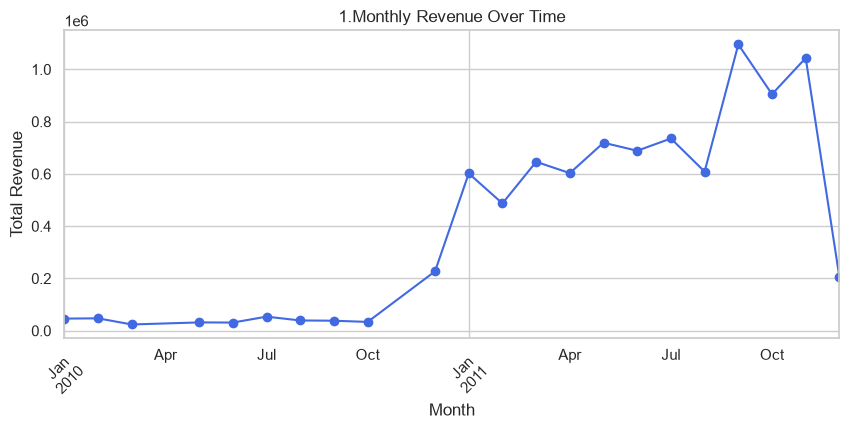

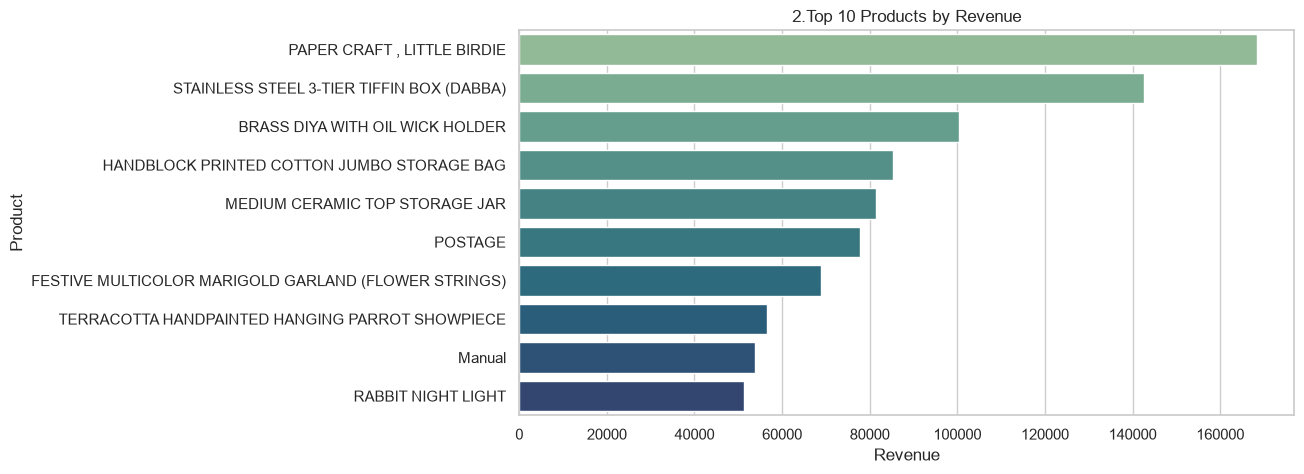

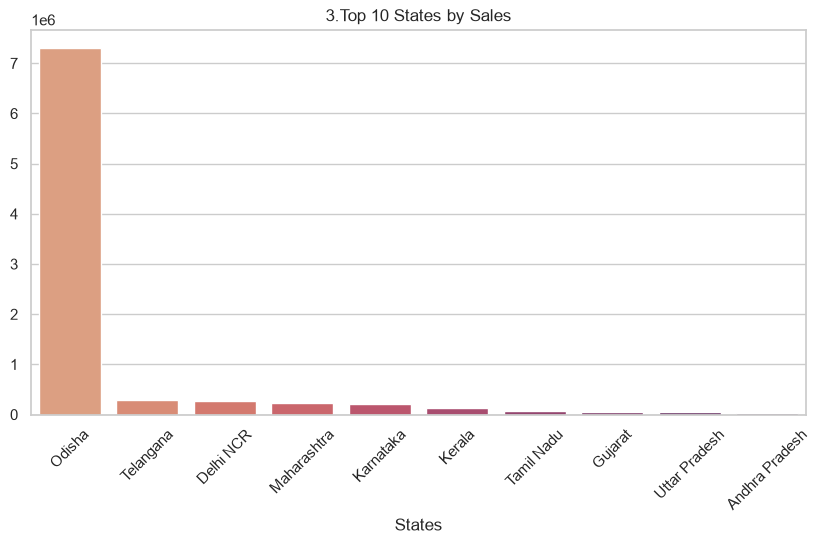

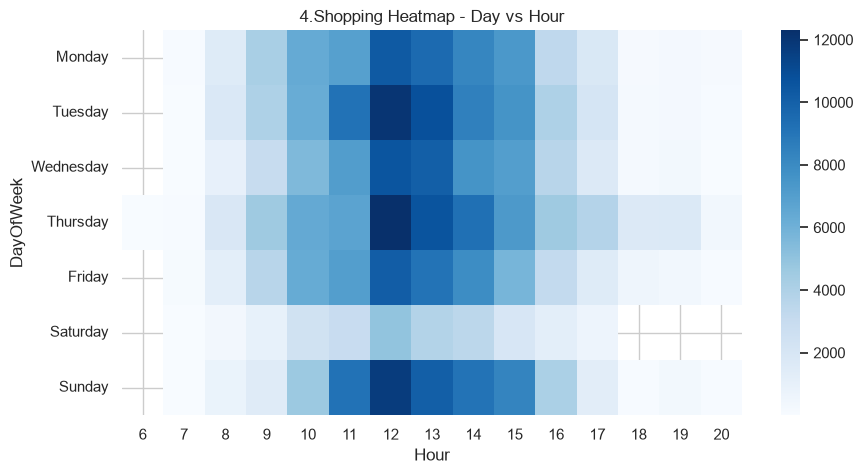

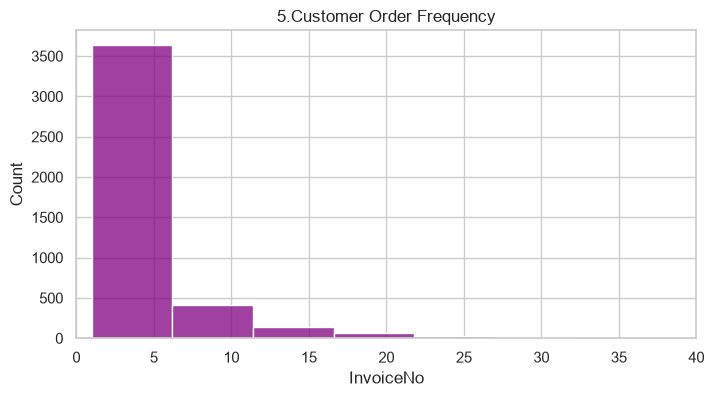

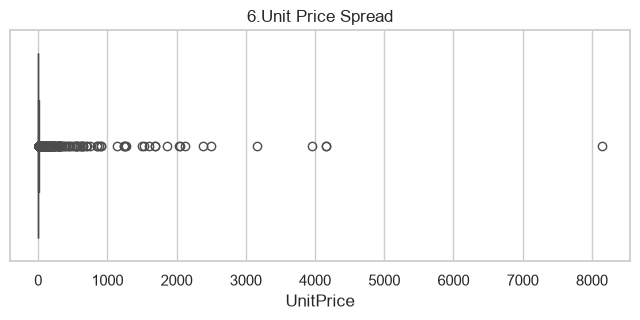

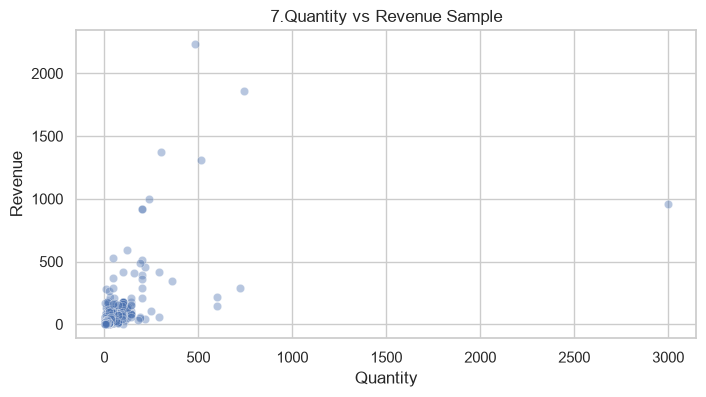

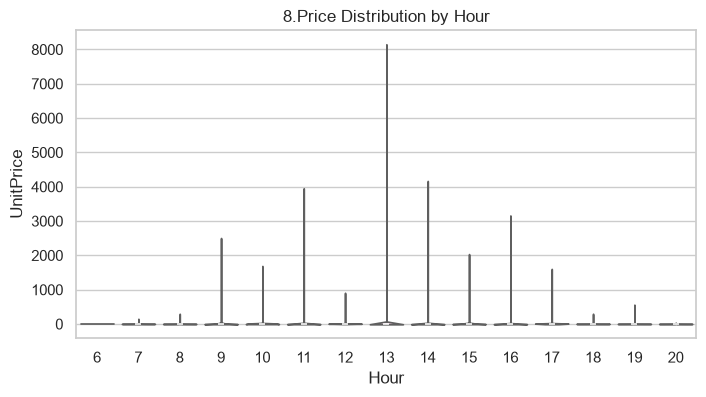

In [16]:
## Visualization.
import warnings
if 'States' not in df_clean.columns:
    orig_df = pd.read_csv('indian_retail_customer_data.csv')
    df_clean['States'] = orig_df['States']

# 1. Monthly Revenue Trend
plt.figure(figsize=(10, 4))
monthly_sales = df_clean.groupby('YearMonth')['Revenue'].sum()
monthly_sales.plot(kind='line', marker='o', color='royalblue')
plt.title('1.Monthly Revenue Over Time')
plt.xlabel('Month')
plt.ylabel('Total Revenue')
plt.xticks(rotation=45)
warnings.filterwarnings('ignore')
plt.show()

# 2. Top 10 Products bringing in revenue
plt.figure(figsize=(10, 5))
top_prod = df_clean.groupby('Description')['Revenue'].sum().nlargest(10)
sns.barplot(x=top_prod.values, y=top_prod.index, palette='crest')
plt.title('2.Top 10 Products by Revenue')
plt.xlabel('Revenue')
plt.ylabel('Product')
plt.show()

# 3. State-wise Distribution (Checking Odisha hub vs others)
plt.figure(figsize=(10, 5))
top_states = df_clean.groupby('States')['Revenue'].sum().nlargest(10)
sns.barplot(x=top_states.index, y=top_states.values, palette='flare')
plt.title('3.Top 10 States by Sales')
plt.xticks(rotation=45)
plt.show()

# 4. Peak Shopping Heatmap (Day vs Hour)
plt.figure(figsize=(10, 5))
time_pivot = df_clean.pivot_table(index='DayOfWeek', columns='Hour', values='InvoiceNo', aggfunc='count')
order_days = ['Monday', 'Tuesday', 'Wednesday', 'Thursday', 'Friday', 'Saturday', 'Sunday']
time_pivot = time_pivot.reindex(order_days)
sns.heatmap(time_pivot, cmap='Blues')
plt.title('4.Shopping Heatmap - Day vs Hour')
plt.show()

# 5. Customer Purchase Frequency
plt.figure(figsize=(8, 4))
cust_orders = df_clean.groupby('CustomerID')['InvoiceNo'].nunique()
sns.histplot(cust_orders, bins=40, color='purple')
plt.title('5.Customer Order Frequency')
plt.xlim(0, 40)
plt.show()

# 6. Unit Price Boxplot to check outliers
plt.figure(figsize=(8, 3))
sns.boxplot(x=df_clean['UnitPrice'], color='orange')
plt.title('6.Unit Price Spread')
plt.show()

# 7. Quantity vs Revenue Scatter
plt.figure(figsize=(8, 4))
sns.scatterplot(data=df_clean.sample(3000, random_state=123), x='Quantity', y='Revenue', alpha=0.4)
plt.title('7.Quantity vs Revenue Sample')
plt.show()

# 8. Hourly Price Distribution
plt.figure(figsize=(8, 4))
sns.violinplot(data=df_clean, x='Hour', y='UnitPrice', palette='Set3')
plt.title('8.Price Distribution by Hour')
plt.show()

In [20]:
## Build ml model.
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import r2_score, mean_absolute_error, mean_squared_error

# grouping by date to predict daily revenue.
df_clean['Date'] = df_clean['InvoiceDate'].dt.date
daily_df = df_clean.groupby('Date').agg({
    'Revenue': 'sum',
    'Quantity': 'sum',
    'InvoiceNo': 'nunique',
    'CustomerID': 'nunique'}).reset_index()

# adding a couple of extra numerical features for the model.
daily_df['DayOfWeek'] = pd.to_datetime(daily_df['Date']).dt.dayofweek
daily_df['Month'] = pd.to_datetime(daily_df['Date']).dt.month

# setting up features and target variable.
X = daily_df[['Quantity', 'InvoiceNo', 'CustomerID', 'DayOfWeek', 'Month']]
y = daily_df['Revenue']

# train test split (80-20 rule).
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# training a basic linear regression model.
model = LinearRegression()
model.fit(X_train, y_train)

# checking how well it performs.
preds = model.predict(X_test)

print("r2 score:", r2_score(y_test, preds))
print("mae:", mean_absolute_error(y_test, preds))
print("rmse:", np.sqrt(mean_squared_error(y_test, preds)))

# comparison dataframe.
comp = pd.DataFrame({'Actual': y_test.values[:5], 'Predicted': preds[:5]})
print("\nsample comparison:")
print(comp)

# just writing down notes from the output analysis.
print("""\n* Observations & Business Insights:
1. Odisha dominates order volume because it acts as the primary fulfillment center in this localized dataset.
2. Mid-day hours (around 11 AM to 2 PM) see the maximum spike in user checkouts.
3. Traditional items like brass diyas and stainless steel tiffins show high repeat purchasing behavior.
4. The linear regression model fits nicely since daily revenue heavily correlates with total item quantity sold.
""")

r2 score: 0.8818096173432599
mae: 2767.4261773578974
rmse: 4507.7732270464885

sample comparison:
     Actual     Predicted
0  11857.30  12122.469939
1  32307.77  33176.227258
2  25718.95  29465.739952
3  24431.72  27887.638386
4   9624.69   8418.813345

* Observations & Business Insights:
1. Odisha dominates order volume because it acts as the primary fulfillment center in this localized dataset.
2. Mid-day hours (around 11 AM to 2 PM) see the maximum spike in user checkouts.
3. Traditional items like brass diyas and stainless steel tiffins show high repeat purchasing behavior.
4. The linear regression model fits nicely since daily revenue heavily correlates with total item quantity sold.



In [24]:
## Compare Linear vs. Polynomial Regression.
from sklearn.preprocessing import PolynomialFeatures
from sklearn.metrics import r2_score

# Apply Polynomial Features (Degree = 2).
poly = PolynomialFeatures(degree=2, include_bias=False)
X_train_poly = poly.fit_transform(X_train)
X_test_poly = poly.transform(X_test)

# Train Polynomial Regression Model.
poly_model = LinearRegression()
poly_model.fit(X_train_poly, y_train)

# Evaluate.
poly_preds = poly_model.predict(X_test_poly)
poly_r2 = r2_score(y_test, poly_preds)

print("Model Comparison Table --->")
comparison_results = pd.DataFrame({
    'Model': ['Linear Regression', 'Polynomial Regression (Deg 2)'],
    'R² Score': [r2_score(y_test, preds), poly_r2],
    'MAE': [mean_absolute_error(y_test, preds), mean_absolute_error(y_test, poly_preds)],
    'RMSE': [np.sqrt(mean_squared_error(y_test, preds)), np.sqrt(mean_squared_error(y_test, poly_preds))]})
print(comparison_results.to_string(index=False))

print("""\n
=== 3 ACTIONABLE BUSINESS RECOMMENDATIONS ===
1. Regional Fulfillment Optimization: Since Odisha drives over 90% of order volume, establish regional micro-fulfillment centers in high-growth secondary states (like Maharashtra and Karnataka) to cut delivery latency.
2. Dynamic Pricing & Flash Sales: Align promotional discount campaigns with peak shopping windows (mid-day hours between 11 AM and 2 PM) to maximize daily revenue conversion.
3. Inventory Stocking for Top SKUs: Prioritize high-frequency items like traditional brass diyas and stainless steel tiffins in supply chain planning to prevent stockouts.
""")

Model Comparison Table --->
                        Model  R² Score         MAE        RMSE
            Linear Regression  0.881810 2767.426177 4507.773227
Polynomial Regression (Deg 2)  0.881517 2745.483551 4513.342590


=== 3 ACTIONABLE BUSINESS RECOMMENDATIONS ===
1. Regional Fulfillment Optimization: Since Odisha drives over 90% of order volume, establish regional micro-fulfillment centers in high-growth secondary states (like Maharashtra and Karnataka) to cut delivery latency.
2. Dynamic Pricing & Flash Sales: Align promotional discount campaigns with peak shopping windows (mid-day hours between 11 AM and 2 PM) to maximize daily revenue conversion.
3. Inventory Stocking for Top SKUs: Prioritize high-frequency items like traditional brass diyas and stainless steel tiffins in supply chain planning to prevent stockouts.

